# v4 — Smoothing antar-window & ensemble

**Pertanyaan.** Apakah pasca-proses tanpa training bisa memperbaiki sistem produksi v3.1?
1. **Smoothing antar-window.** Episode AFL berlangsung menit, dan 91% AFL palsu v3 muncul di sekitar episode. Probabilitas
   tiap window dihaluskan dengan window lain dari rekaman yang sama: rata-rata bergerak atau HMM. Versi **offline** memakai
   window sebelum *dan* sesudahnya (cocok untuk `predict_ecg` atas rekaman utuh); versi **real-time** hanya ke belakang.
2. **Ensemble MicroTransformer + BiGRU.** Skor keduanya setara di v3, tapi pola recall per pasiennya berbeda.

**Varian utama** (ditetapkan sebelum melihat hasil): MT + smoothing offline, MT + smoothing real-time, ensemble MT+BiGRU,
dan ensemble + smoothing offline / real-time. Ensemble 4 model hanya eksploratif.

**Kejujuran evaluasi.** Untuk tiap fold uji, konfigurasi smoothing (termasuk "tanpa smoothing") **dan** bias kelas dipilih dari
fold lain (cross-fit), lalu dipakai pada fold uji. Fold, seed, dan bootstrap sama dengan v3. Referensi = **v3.1**
(MicroTransformer, bias cross-fit grid −7…+3).

**Metrik tambahan: level episode.** Episode = deret window bersambung (jeda ≤ 10 s). *Alarm AFL palsu* = episode prediksi AFL
yang tidak menyentuh AFL sebenarnya, dihitung per jam rekaman. *Deteksi episode* = episode AFL sebenarnya yang punya ≥ 1 window
tertebak AFL.

Prasyarat: OOF v3 (`../cache/oof_robust/detector_e30_r5_s2026/`). Tidak ada training dan tidak menyentuh paket produksi.
Logika ada di `pascaproses.py`.

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pascaproses as S
cv = S.cv
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 30)


def fmt(v, nd=3):
    return f"{v[0]:.{nd}f} [{v[1]:.2f}–{v[2]:.2f}]"


def verdict(p):
    return "lebih baik" if p >= .95 else "lebih buruk" if p <= .05 else "tidak terbedakan"

## 1. Data & uji fungsi smoothing

In [2]:
d = S.load()
assert all(np.all(np.diff(d.t[s:e]) > 0) for s, e in d.bounds), "window tidak urut waktu"
assert len(d.bounds) == len(d.patients), "satu rekaman harus kontigu"
gaps = np.concatenate([np.diff(d.t[s:e]) for s, e in d.bounds])
print(f"{d.y.size:,} window, {len(d.bounds)} rekaman | jarak antar window: median {np.median(gaps):.0f} s, "
      f"persentil 99 {np.percentile(gaps, 99):.0f} s")

rng = np.random.default_rng(0)
t = np.r_[np.arange(0, 750, 5.0), np.arange(900, 1650, 5.0)]
bnd = [(0, 150), (150, 300)]
P = rng.dirichlet([1, 1, 1], 300)
assert np.allclose(S.smooth_mean(P, t, bnd, 0, False), P)                       # lebar 0 = identitas
for causal in (True, False):                                                     # transisi seragam = identitas
    assert np.allclose(S.smooth_hmm(P, t, bnd, 1 / 3, causal), P / P.sum(1, keepdims=True), atol=1e-9)
P2 = P.copy(); P2[150:] = rng.dirichlet([1, 1, 1], 150)                          # tidak bocor antar rekaman
P3 = P.copy(); P3[149] = [1, 0, 0]                                               # kausal tidak melihat masa depan
for f in (lambda Q: S.smooth_mean(Q, t, bnd, 60, False), lambda Q: S.smooth_hmm(Q, t, bnd, .97, False)):
    assert np.allclose(f(P)[:150], f(P2)[:150])
for f in (lambda Q: S.smooth_mean(Q, t, bnd, 60, True), lambda Q: S.smooth_hmm(Q, t, bnd, .97, True)):
    assert np.allclose(f(P)[:149], f(P3)[:149])
print("✓ uji smoothing lolos (identitas, tanpa kebocoran antar rekaman, kausal benar)")
print("Kandidat offline  :", [S.cfg_name(c) for c in S.OFFLINE])
print("Kandidat real-time:", [S.cfg_name(c) for c in S.REALTIME])

165,978 window, 23 rekaman | jarak antar window: median 5 s, persentil 99 6 s
✓ uji smoothing lolos (identitas, tanpa kebocoran antar rekaman, kausal benar)
Kandidat offline  : ['tanpa smoothing', 'rata-rata ±15 s', 'rata-rata ±30 s', 'rata-rata ±60 s', 'rata-rata ±120 s', 'HMM p=0.9', 'HMM p=0.97', 'HMM p=0.99']
Kandidat real-time: ['tanpa smoothing', 'rata-rata kausal 15 s', 'rata-rata kausal 30 s', 'rata-rata kausal 60 s', 'rata-rata kausal 120 s', 'HMM kausal p=0.9', 'HMM kausal p=0.97', 'HMM kausal p=0.99']


## 2. Prediksi semua varian (cross-fit, paralel per ulangan)

±10 menit. Hasil disimpan di `../cache/v4/pred.npz`; run berikutnya langsung memuat.

In [3]:
t0 = time.perf_counter()
pred, chosen, per_cfg = S.run_predictions()
print(f"{len(pred)} varian × {S.N_REPEATS} ulangan | {time.perf_counter() - t0:.0f}s")

8 varian × 5 ulangan | 807s


## 3. Hasil utama

Semua baris: window uji detektor 50 Hz, rata-rata 5 ulangan, CI 95% bootstrap pasien (sampel bootstrap sama).

In [4]:
ev = S.evaluate(d, pred)
order = list(S.VARIANTS)
RES = pd.DataFrame([{"Varian": S.VARIANTS[k][0],
                     **{m: fmt(ev.rows[k][m]) for m in ("Macro-F1", "AFL F1", "AFL P", "AFL R", "Normal R")},
                     "alarm AFL palsu/jam": fmt(ev.epi[k]["alarm/jam"], 3),
                     "deteksi episode AFL": fmt(ev.epi[k]["deteksi episode"], 2)} for k in order]).set_index("Varian")
display(RES)

ref_v3 = pd.read_csv(S.OOF_DIR / "ringkasan.csv").set_index("Model").loc["MicroTransformer +bias", "Macro-F1"]
assert ref_v3.startswith(f"{ev.rows['v31']['Macro-F1'][0]:.3f}"), (ref_v3, ev.rows["v31"]["Macro-F1"])
print("✓ Referensi identik dengan v3/v3.1:", ref_v3)
print(f"Episode AFL sebenarnya: {ev.epi['v31']['episode AFL']} dalam {ev.epi['v31']['jam']:.0f} jam rekaman")

,Macro-F1,AFL F1,AFL P,AFL R,Normal R,alarm AFL palsu/jam,deteksi episode AFL
Varian,,,,,,,
"v1 (sebelum revisi), argmax",0.744 [0.64–0.81],0.399 [0.09–0.59],0.275 [0.05–0.46],0.728 [0.37–0.98],0.903 [0.82–0.95],5.101 [2.69–7.89],0.91 [0.73–1.00]
v3.1 referensi: MicroTransformer,0.832 [0.67–0.92],0.647 [0.17–0.89],0.715 [0.26–0.95],0.592 [0.13–0.91],0.924 [0.84–0.97],0.512 [0.10–1.07],0.74 [0.42–0.93]
MicroTransformer + smoothing offline,0.810 [0.67–0.91],0.533 [0.13–0.81],0.746 [0.18–0.88],0.417 [0.08–0.80],0.953 [0.88–0.99],0.087 [0.03–0.16],0.38 [0.08–0.64]
MicroTransformer + smoothing real-time,0.806 [0.65–0.89],0.536 [0.10–0.79],0.667 [0.12–0.81],0.449 [0.08–0.83],0.953 [0.89–0.99],0.193 [0.10–0.30],0.45 [0.18–0.65]
Ensemble MT + BiGRU,0.835 [0.68–0.93],0.637 [0.17–0.92],0.718 [0.23–0.95],0.573 [0.15–0.95],0.935 [0.87–0.97],0.453 [0.09–0.91],0.74 [0.42–0.94]
Ensemble MT + BiGRU + smoothing offline,0.803 [0.68–0.91],0.494 [0.13–0.81],0.703 [0.18–0.87],0.382 [0.09–0.81],0.965 [0.91–0.99],0.075 [0.02–0.14],0.38 [0.08–0.64]
Ensemble MT + BiGRU + smoothing real-time,0.794 [0.66–0.89],0.490 [0.10–0.77],0.618 [0.11–0.77],0.407 [0.09–0.84],0.959 [0.90–0.99],0.231 [0.10–0.38],0.48 [0.22–0.68]
Ensemble 4 model (eksploratif),0.803 [0.68–0.84],0.534 [0.16–0.63],0.590 [0.14–0.79],0.494 [0.18–0.63],0.945 [0.88–0.98],0.699 [0.24–1.24],0.82 [0.60–0.97]


✓ Referensi identik dengan v3/v3.1: 0.832 [0.67–0.92]
Episode AFL sebenarnya: 13 dalam 234 jam rekaman


In [5]:
PAIR = pd.DataFrame([{"Varian": S.VARIANTS[k][0],
                      **{f"Δ {m}": f"{v[0]:+.3f} [{v[1]:+.2f}…{v[2]:+.2f}]" for m, v in ev.pairs[k].items()
                         if m in ("Macro-F1", "AFL F1", "Normal R", "alarm/jam", "deteksi episode")},
                      "P(Δ MF1>0)": round(ev.pairs[k]["Macro-F1"][3], 2),
                      "vonis Macro-F1": verdict(ev.pairs[k]["Macro-F1"][3]),
                      "P(alarm/jam turun)": round(1 - ev.pairs[k]["alarm/jam"][3], 2)}
                     for k in order if k != S.REF]).set_index("Varian")
print("Δ terhadap referensi v3.1 (berpasangan). Untuk alarm/jam, turun = lebih baik.")
display(PAIR)

Δ terhadap referensi v3.1 (berpasangan). Untuk alarm/jam, turun = lebih baik.


,Δ Macro-F1,Δ AFL F1,Δ Normal R,Δ alarm/jam,Δ deteksi episode,P(Δ MF1>0),vonis Macro-F1,P(alarm/jam turun)
Varian,,,,,,,,
"v1 (sebelum revisi), argmax",-0.088 [-0.16…-0.02],-0.249 [-0.47…-0.05],-0.020 [-0.03…-0.01],+4.588 [+2.58…+6.88],+0.169 [+0.03…+0.42],0.02,lebih buruk,0.00
MicroTransformer + smoothing offline,-0.021 [-0.04…+0.02],-0.114 [-0.19…+0.01],+0.029 [+0.02…+0.04],-0.425 [-0.92…-0.05],-0.354 [-0.65…-0.05],0.11,tidak terbedakan,1.00
MicroTransformer + smoothing real-time,-0.025 [-0.05…+0.00],-0.111 [-0.20…-0.02],+0.029 [+0.02…+0.04],-0.319 [-0.79…+0.03],-0.292 [-0.52…-0.05],0.03,lebih buruk,0.93
Ensemble MT + BiGRU,+0.004 [-0.01…+0.02],-0.011 [-0.04…+0.03],+0.012 [+0.01…+0.02],-0.059 [-0.18…+0.02],+0.000 [-0.04…+0.06],0.72,tidak terbedakan,0.85
Ensemble MT + BiGRU + smoothing offline,-0.028 [-0.06…+0.02],-0.153 [-0.25…+0.01],+0.041 [+0.02…+0.07],-0.437 [-0.94…-0.06],-0.354 [-0.65…-0.05],0.16,tidak terbedakan,1.00
Ensemble MT + BiGRU + smoothing real-time,-0.038 [-0.07…+0.00],-0.157 [-0.24…-0.04],+0.036 [+0.02…+0.06],-0.282 [-0.75…+0.03],-0.262 [-0.49…-0.05],0.03,lebih buruk,0.93
Ensemble 4 model (eksploratif),-0.029 [-0.09…+0.02],-0.113 [-0.31…+0.02],+0.021 [+0.01…+0.04],+0.187 [+0.02…+0.37],+0.077 [-0.03…+0.28],0.22,tidak terbedakan,0.02


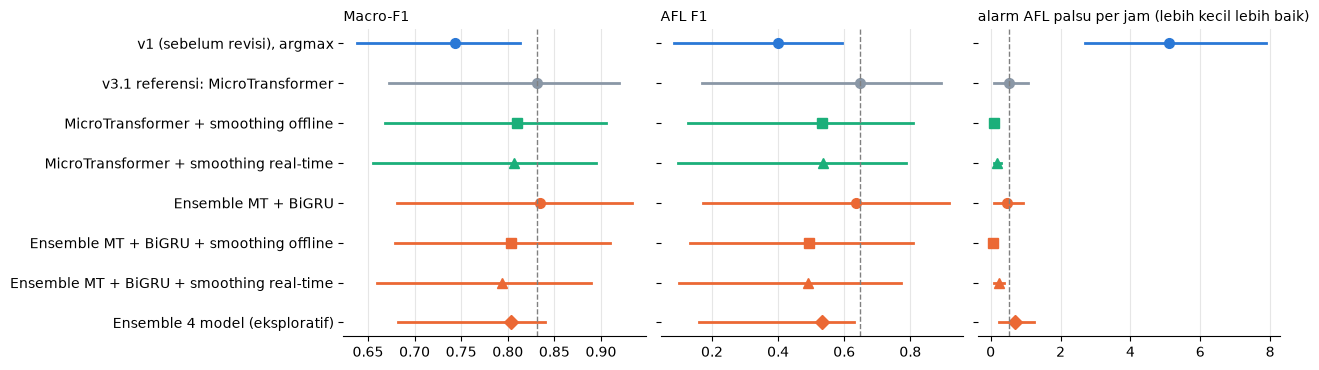

In [6]:
COLOR = {"v1": "#2a78d6", "v31": "#8A97A6", "mt_off": "#1baf7a", "mt_rt": "#1baf7a",
         "e1": "#eb6834", "e1_off": "#eb6834", "e1_rt": "#eb6834", "e2": "#eb6834"}
MARK = {"v1": "o", "v31": "o", "mt_off": "s", "mt_rt": "^", "e1": "o", "e1_off": "s", "e1_rt": "^", "e2": "D"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (m, src) in zip(axes, (("Macro-F1", "rows"), ("AFL F1", "rows"), ("alarm/jam", "epi"))):
    for i, k in enumerate(order):
        pt, lo, hi = (ev.rows if src == "rows" else ev.epi)[k][m]
        ax.plot([lo, hi], [i, i], color=COLOR[k], lw=2)
        ax.plot(pt, i, MARK[k], color=COLOR[k], ms=7)
    ref = (ev.rows if src == "rows" else ev.epi)["v31"][m][0]
    ax.axvline(ref, color="0.5", lw=1, ls="--")
    ax.set_title(m if m != "alarm/jam" else "alarm AFL palsu per jam (lebih kecil lebih baik)", loc="left", fontsize=10)
    ax.grid(axis="x", color="0.9"); ax.set_axisbelow(True)
    for s_ in ("top", "right", "left"):
        ax.spines[s_].set_visible(False)
axes[0].set_yticks(range(len(order)), [S.VARIANTS[k][0] for k in order]); axes[0].invert_yaxis()
plt.tight_layout(); plt.show()

## 4. Konfigurasi yang dipilih cross-fit, dan kurva per konfigurasi

Tabel pertama: berapa kali tiap konfigurasi terpilih (25 fold per varian). Tabel kedua: hasil jika satu konfigurasi
**dipaksa** untuk semua fold (bias tetap cross-fit). Ini diagnostik untuk melihat bentuk kurvanya, bukan seleksi yang jujur.

In [7]:
summary = S.assemble(d, pred, chosen, per_cfg, ev)
display(pd.DataFrame({S.VARIANTS[k][0]: pd.Series(v) for k, v in summary["chosen"].items()
                      if k in ("mt_off", "mt_rt", "e1_off", "e1_rt")}).fillna(0).astype(int))
display(pd.DataFrame(summary["per_cfg"]).T.round(3))

,MicroTransformer + smoothing offline,MicroTransformer + smoothing real-time,Ensemble MT + BiGRU + smoothing offline,Ensemble MT + BiGRU + smoothing real-time
HMM kausal p=0.9,0,0,0,1
HMM kausal p=0.97,0,1,0,2
rata-rata kausal 120 s,0,18,0,13
rata-rata kausal 15 s,0,2,0,2
rata-rata kausal 30 s,0,3,0,3
rata-rata kausal 60 s,0,1,0,4
rata-rata ±120 s,20,0,20,0
rata-rata ±15 s,4,0,5,0
rata-rata ±30 s,1,0,0,0


,Macro-F1,AFL F1,Normal R,alarm/jam
tanpa smoothing,0.832,0.647,0.924,0.512
rata-rata ±15 s,0.814,0.553,0.951,0.262
rata-rata ±30 s,0.806,0.514,0.958,0.149
rata-rata ±60 s,0.819,0.559,0.961,0.095
rata-rata ±120 s,0.836,0.615,0.953,0.060
HMM p=0.9,0.830,0.594,0.933,0.581
HMM p=0.97,0.822,0.563,0.933,0.502
HMM p=0.99,0.825,0.571,0.932,0.400
rata-rata kausal 15 s,0.832,0.613,0.942,0.223
rata-rata kausal 30 s,0.806,0.537,0.948,0.267


## 5. AFL per pasien

In [8]:
AFL = pd.DataFrame({S.VARIANTS[k][0]: ev.afl_recall[k] for k in ("v1", "v31", "mt_off", "e1", "e1_off")},
                   index=ev.afl_patients).round(2)
AFL.index.name = "recall AFL per pasien"
display(AFL)

,"v1 (sebelum revisi), argmax",v3.1 referensi: MicroTransformer,MicroTransformer + smoothing offline,Ensemble MT + BiGRU,Ensemble MT + BiGRU + smoothing offline
recall AFL per pasien,,,,,
04043,1.00,0.40,0.00,0.60,0.00
04908,1.00,0.92,0.80,0.95,0.84
04936,0.67,0.51,0.28,0.45,0.21
06426,0.73,0.17,0.00,0.23,0.00
07910,0.21,0.00,0.00,0.00,0.00
08215,0.04,0.00,0.00,0.00,0.00
08378,1.00,0.96,0.84,1.00,0.85


In [9]:
S.CACHE_OUT.mkdir(parents=True, exist_ok=True)
(S.CACHE_OUT / "ringkasan.json").write_text(json.dumps(summary, indent=1, ensure_ascii=False))
best = max(S.PRIMARY, key=lambda k: ev.rows[k]["Macro-F1"][0])
for k in S.PRIMARY:
    p = ev.pairs[k]
    print(f"{S.VARIANTS[k][0]:<45} Δ Macro-F1 {p['Macro-F1'][0]:+.3f} (P={p['Macro-F1'][3]:.2f}, {verdict(p['Macro-F1'][3])}) | "
          f"alarm/jam {ev.epi[k]['alarm/jam'][0]:.3f} vs {ev.epi['v31']['alarm/jam'][0]:.3f}")
print(f"Macro-F1 tertinggi di antara varian utama: {S.VARIANTS[best][0]}")
print(f"Ringkasan → {S.CACHE_OUT.relative_to(S.REPO)}/ringkasan.json")

MicroTransformer + smoothing offline          Δ Macro-F1 -0.021 (P=0.11, tidak terbedakan) | alarm/jam 0.087 vs 0.512
MicroTransformer + smoothing real-time        Δ Macro-F1 -0.025 (P=0.03, lebih buruk) | alarm/jam 0.193 vs 0.512
Ensemble MT + BiGRU                           Δ Macro-F1 +0.004 (P=0.72, tidak terbedakan) | alarm/jam 0.453 vs 0.512
Ensemble MT + BiGRU + smoothing offline       Δ Macro-F1 -0.028 (P=0.16, tidak terbedakan) | alarm/jam 0.075 vs 0.512
Ensemble MT + BiGRU + smoothing real-time     Δ Macro-F1 -0.038 (P=0.03, lebih buruk) | alarm/jam 0.231 vs 0.512
Macro-F1 tertinggi di antara varian utama: Ensemble MT + BiGRU
Ringkasan → cache/v4/ringkasan.json


## 6. Kesimpulan

**Tidak ada varian yang lebih baik dari v3.1 secara konsisten. Paket produksi tetap v3.1; v4 tidak dikemas.**

- **Ensemble MT + BiGRU.** Setara dengan v3.1: Macro-F1 0,835 vs 0,832 (Δ +0,004 [−0,01…+0,02], P = 0,72). Satu-satunya
  efek yang konsisten adalah recall Normal +0,012. Tidak sebanding dengan biaya melatih dan mengirim model final kedua.
- **Smoothing offline** adalah *tukar-menukar*, bukan perbaikan. Efek yang konsisten:
  - alarm AFL palsu turun dari 0,51 ke 0,09 per jam (P = 1,00);
  - recall Normal naik +0,029;
  - deteksi episode AFL turun dari 74% ke 38%, karena episode pendek ikut hilang (04043, 06426 → 0).

  Dalam Macro-F1 window ia tidak terbedakan (P = 0,11). Cross-fit hampir selalu memilih rata-rata ±120 s.
- **Smoothing real-time** lebih buruk dari v3.1 (P = 0,03), dengan pola trade-off yang sama tapi lebih lemah.
- **Dari kurva per konfigurasi:** tidak ada konfigurasi yang menaikkan AFL F1 di atas tanpa smoothing (0,647). Bukti AFL di data
  ini memang ada di window-window yang terisolasi.
- **Keputusan produk (bukan teknis).** Smoothing offline bisa ditawarkan sebagai mode "hemat alarm" jika tim menilai alarm palsu
  lebih mahal daripada AFL yang terlewat.

**Langkah berikutnya (v5, perlu training):**
- window AFL rapat khusus training;
- bobot kelas lebih lunak;
- cabang EKG mentah untuk pasien yang gagal di semua versi (07910, 08215, 06426).